# 12 - Core Calibration and the Digital Core

**Part B - Petrophys Curriculum**

Wireline logs are *indirect* measurements. A neutron tool counts hydrogen, a
density tool counts back-scattered gamma rays - neither one *is* porosity. The
ground truth against which every log interpretation is ultimately judged is the
**core**: a physical cylinder of rock brought to surface and measured in the
laboratory.

This lesson has four parts:

1. **Core-to-log calibration** - tie laboratory helium porosity and Klinkenberg
   permeability to the logs, quantify the mismatch ($R^2$, bias, RMSE), and fit a
   **poro-perm transform** so we can predict permeability everywhere the core did
   not sample.
2. **Rock typing on the cored interval** - cluster real wireline logs into
   **electrofacies** with weighted K-means (`DigitalCoreFacies`), fingerprint
   each cluster with per-facies statistics, and read the clusters on a
   density-neutron cross-plot.
3. **Geochemistry from spectral gamma** - read thorium and uranium logs for
   depositional environment (the Th/U ratio), and build a thorium clay
   indicator that shows where uranium corrupts the GR clay volume.
4. **A second well's core** - repeat the calibration on another cored well,
   repair its core-to-log depth tie, and test whether a poro-perm transform
   carries from one well to the other.

Parts 1 and 2 use the cored well **30/6-5** (Oseberg, North Sea). Parts 3 and 4
use **25/5-1** (Frøy, North Sea), which carries spectral gamma and core plugs.
The library also ships digital-core readers (`XRFData`, `GrainSizeData`,
`CoreMechanical`) and an Epslog collection for **15/12-20 S**, with a matching
routine-core extract. Sections 2.2-2.4 identify these new inputs and the remaining
calibration checks; their full notebook exercises are still pending. Part 3
demonstrates the spectral geochemistry measured downhole on 25/5-1.

## Learning goals

By the end of this lesson you will be able to:

- Build a `CoreData` container directly from a cored well with
  `core_data_from_well` (from `petrophys.interpretation.core_analysis`).
- Calibrate a log-derived porosity against core with `calibrate_porosity`, and
  read the calibration statistics off a `CalibrationResult`.
- Fit a linear porosity correction (`fit_porosity_correction`) and a poro-perm
  transform (`fit_poro_perm_transform`), apply the transform to the log, and
  judge where the prediction is supported by core and where it extrapolates.
- Cluster wireline logs over the cored interval into electrofacies with
  `DigitalCoreFacies` / `FaciesResult`, and produce a per-facies statistics
  table.
- Check processed spectral gamma curves for units, coverage and plausibility
  (including held readings at the bottom of a logging run, with
  `find_held_readings`), then interpret them with `interpret_spectral_gamma`.
- Read the Th/U ratio against the standard thresholds for depositional
  environment (`classify_th_u_environment`), and compare a thorium clay
  indicator with the GR clay volume to locate where uranium biases it.
- Diagnose a core-to-log depth offset with `find_core_depth_shift`, and test
  whether a poro-perm transform carries from one well to another.

## Why this matters

Every deterministic petrophysical answer - porosity, saturation, net pay,
volumes - inherits the systematic error of the logs it was built from. Core
calibration is how we *anchor* those logs to reality:

- **Porosity** measured by a density tool depends on an assumed matrix density.
  Get the grain density wrong and every porosity is biased. Core helium porosity
  fixes the tie point.
- **Permeability** is never measured by wireline; it is *always* a correlation.
  A poro-perm transform fitted to core plugs is the standard way to propagate a
  handful of lab measurements to the full log.
- **Clay volume** is usually read from GR, on the assumption that all
  radioactivity comes from clay. A spectral gamma log splits GR into potassium,
  thorium and uranium, which shows when that assumption fails.

The **digital core** pushes this further. Instead of one plug every ~30 cm,
modern core scanners deliver *continuous* millimetre-to-centimetre logs of grain
size, elemental chemistry, strength, and colour. Clustering these into facies
gives a rock-typing scheme that is fully data-driven and reproducible - the
kind of product commercial core-scanning services deliver.

Finally, calibrations and transforms are built in the wells that have core and
then reused in wells that do not. Checking them against a second cored well is
how you find out whether that reuse is safe.

> **Units convention.** In `petrophys`, porosity and saturation are stored as
> **fractions (v/v, 0-1)**, permeability in **mD**, grain/bulk density in
> **g/cm3**, thorium and uranium in **ppm**, and potassium in **%**.

### Prerequisites

Assumes the Part A clay volume, porosity and permeability lessons (03, 04, 08).
Part 2 uses `DigitalCoreFacies`, which needs **scikit-learn** for K-means
clustering. Install it with the machine-learning extra (Python 3.11 or later):

```bash
pip install "petrophys[ml]"
```

Parts 1, 3 and 4 run with the base installation.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp

print("petrophys", pp.__version__)
print("geolink wells:", pp.list_samples("geolink"))

petrophys 3.0.0
geolink wells: ['15_9-14', '16_7-1', '25_5-1', '30_6-5']


---
## Part 1 - Core-to-log calibration

### 1.1 Loading core measurements from the well

Well **30/6-5** is unusual and convenient: it ships with the laboratory core
measurements already merged into the LAS file as dedicated curves -
`PHIC` (core helium porosity), `KH_CORE` (horizontal Klinkenberg permeability),
`GDEN` (grain density), and `SWC` / `SOC` (Dean-Stark saturations).

`core_data_from_well` sweeps the well for these mnemonics and packs the samples
that actually carry a lab measurement into a `CoreData` object.

In [2]:
well = pp.read(pp.sample("30_6-5"))

# Sanitize the field name for ASCII printing (this header has mojibake).
field_ascii = (well.header.field or "Unknown").encode("ascii", "replace").decode("ascii")
print("Well :", well.name, "| field:", field_ascii)
print("Depth: %.1f - %.1f %s" % (well.start_depth, well.stop_depth, well.depth_unit))
print("Curves present:", ", ".join(well.curves))

Well : 30/6-5 | field: OSEBERG ?ST
Depth: 176.6 - 3556.1 m
Curves present: LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC


In [3]:
import warnings
from petrophys.interpretation.core_analysis import core_data_from_well

# core_data_from_well returns core saturations as fractions. This well stores
# SWC/SOC as percent labelled 'frac', so it converts them and says so.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    core = core_data_from_well(well)
for note in caught:
    print("note:", note.message)
print(core)
print()
print('Plugs                :', core.n_plugs)
print('Cored interval       : %.1f - %.1f %s' % (core.top, core.bottom, well.depth_unit))
print('Porosity source curve:', core.metadata.get('core_porosity_curve'))
print('Perm source curve    :', core.metadata.get('core_permeability_curve'))
print('GD source curve      :', core.metadata.get('core_grain_density_curve'))
print()
print('Valid porosity plugs :', int(np.isfinite(core.porosity).sum()))
print('Valid perm plugs     :', int(np.isfinite(core.permeability).sum()))
print('Core porosity range  : %.3f - %.3f v/v' % (np.nanmin(core.porosity), np.nanmax(core.porosity)))
print('Core perm range      : %.2f - %.1f mD' % (np.nanmin(core.permeability), np.nanmax(core.permeability)))

note: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
note: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
CoreData(plugs=201, depth=2800.5-2947.9, props=[porosity, perm, GD, Sw])

Plugs                : 201
Cored interval       : 2800.5 - 2947.9 m
Porosity source curve: PHIC
Perm source curve    : KH_CORE
GD source curve      : GDEN

Valid porosity plugs : 200
Valid perm plugs     : 198
Core porosity range  : 0.022 - 0.277 v/v
Core perm range      : 0.02 - 5826.0 mD


### 1.2 Calibrating an *independent* log porosity

To calibrate honestly we must compare core against a log porosity that was
computed **independently** of the core. (Comparing `PHIC` against itself would
trivially give $R^2 = 1$.) So we compute a fresh **density porosity** from the
bulk-density curve using the textbook relation

$$\phi_D = \frac{\rho_{ma} - \rho_b}{\rho_{ma} - \rho_f}$$

with an *assumed* sandstone matrix density $\rho_{ma} = 2.65$ g/cm3 and fluid
density $\rho_f = 1.0$ g/cm3. The whole point of calibration is to discover how
wrong those assumptions are.

In [4]:
RHO_MA = 2.65   # assumed quartz matrix density (g/cm3)
RHO_F  = 1.00   # assumed fluid density (g/cm3)

rhob = np.asarray(well.get('RHOB').data, dtype=float)
phid = np.clip((RHO_MA - rhob) / (RHO_MA - RHO_F), 0.0, 0.5)
well.add_curve('PHID', phid, 'v/v', 'Density porosity (rho_ma=2.65)')

print('PHID added. Mean density porosity: %.3f v/v' % np.nanmean(phid))

PHID added. Mean density porosity: 0.286 v/v


In [5]:
from petrophys.interpretation.core_analysis import calibrate_porosity

cal = calibrate_porosity(well, core, log_curve='PHID')
print('Core vs log density-porosity calibration')
print('  n points  :', cal.n_points)
print('  R^2       : %.3f' % cal.r_squared)
print('  Bias (log-core): %+.4f v/v' % cal.bias)
print('  RMSE      : %.4f v/v' % cal.rmse)
print('  Linear fit: log = %.3f * core + %.4f' % (cal.slope, cal.intercept))

Core vs log density-porosity calibration
  n points  : 200
  R^2       : 0.645
  Bias (log-core): -0.0198 v/v
  RMSE      : 0.0461 v/v
  Linear fit: log = 0.860 * core + 0.0045


A **positive bias** means the log reads systematically *higher* than core; a
negative bias means it reads low. Read the sign and size of the bias printed
above: on 30/6-5 the density porosity runs **low** relative to core, and the
scatter ($R^2$ well below 1) reflects the assumed matrix density not being
exactly right for every plug - exactly the kind of systematic error
calibration exists to expose.

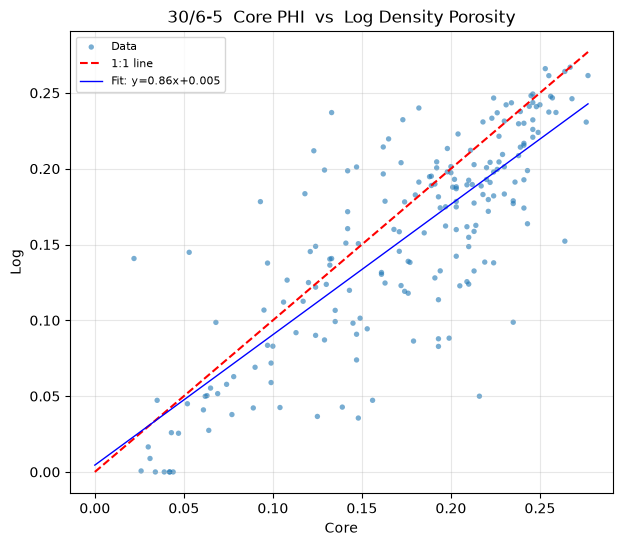

In [6]:
from petrophys.visualization.core import plot_calibration

fig, ax = plot_calibration(cal, title='30/6-5  Core PHI  vs  Log Density Porosity')
plt.show()

### 1.3 A porosity correction

`fit_porosity_correction` fits $\phi_{core} = A\,\phi_{log} + B$ so we can map
the *full* log porosity onto its core-equivalent value. This is the transfer
function you would apply downstream before computing volumes.

In [7]:
from petrophys.interpretation.core_analysis import fit_porosity_correction

corr = fit_porosity_correction(well, core, log_curve='PHID')
print(corr)
print()
# Apply to two example log readings
for phi_log in (0.10, 0.25):
    print('  log phi %.2f -> core-equivalent %.3f' % (phi_log, float(corr.predict(phi_log))))

PorosityCorrection(PHIcore = 0.717*PHID + 0.065, R^2=0.580, RMSE=0.0383, n=193)

  log phi 0.10 -> core-equivalent 0.136
  log phi 0.25 -> core-equivalent 0.244


### 1.4 Fitting a poro-perm transform

Permeability spans orders of magnitude, so the industry-standard transform is
linear in **log10** space:

$$\log_{10}(k) = A\,\phi + B \quad\Longleftrightarrow\quad k = 10^{B}\,10^{A\phi}$$

`fit_poro_perm_transform` fits this straight from the `CoreData` porosity and
permeability arrays.

In [8]:
from petrophys.interpretation.core_analysis import fit_poro_perm_transform

transform = fit_poro_perm_transform(core)
print('Poro-perm transform (log10 K = A*phi + B)')
print('  A (slope)    : %.2f' % transform.A)
print('  B (intercept): %.2f' % transform.B)
print('  R^2          : %.3f' % transform.r_squared)
print('  n plugs      :', transform.n_points)
print()
for phi in (0.10, 0.20, 0.30):
    print('  phi %.2f -> k = %.2f mD' % (phi, float(transform.predict(phi))))

Poro-perm transform (log10 K = A*phi + B)
  A (slope)    : 21.72
  B (intercept): -2.54
  R^2          : 0.777
  n plugs      : 198

  phi 0.10 -> k = 0.43 mD
  phi 0.20 -> k = 64.23 mD
  phi 0.30 -> k = 9540.29 mD


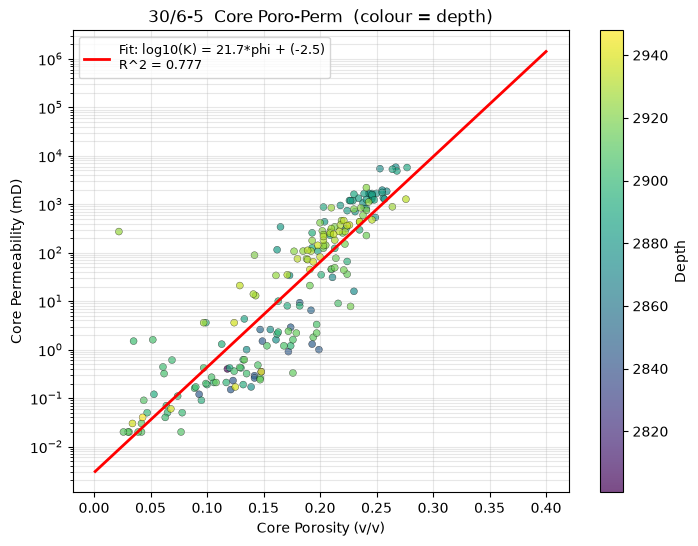

In [9]:
from petrophys.visualization.core import plot_poro_perm

fig, ax = plot_poro_perm(core, transform=transform,
                         title='30/6-5  Core Poro-Perm  (colour = depth)')
plt.show()

### 1.5 Applying the transform back onto the log

`apply_poro_perm_transform` writes a continuous predicted-permeability curve onto
the well using a chosen porosity input. We feed it our density porosity, so the
curve covers the *entire* logged interval, not just the cored plugs. We store
it as `PERM_CORE`, a name the core-overlay plotter recognises, so the next
figure can overlay the measured plugs on the prediction.

A transform is only supported where the plugs are: the cored interval (here
inside the Brent reservoir) and the porosity range the plugs span. Outside
that, it **extrapolates**. In the shallow, poorly compacted section the density
porosity is very high, the exponential transform explodes, and the function
clips the result at its 100,000 mD ceiling. So we summarise the prediction
over the cored interval only, and count how many samples elsewhere hit the
ceiling.

In [10]:
from petrophys.interpretation.core_analysis import apply_poro_perm_transform

perm_pred = apply_poro_perm_transform(well, transform,
                                      porosity_curve="PHID",
                                      output_curve="PERM_CORE")
print("Predicted permeability curve PERM_CORE added to well.")

depth = np.asarray(well.depth, dtype=float)
cored = (depth >= core.top) & (depth <= core.bottom) & np.isfinite(perm_pred)
k_cored = perm_pred[cored]
print()
print("Cored interval %.1f-%.1f m (%d log samples):" % (core.top, core.bottom, k_cored.size))
print("  log-predicted k: median %.2f mD, P10 / P90 %.3f / %.1f mD"
      % (np.median(k_cored), np.percentile(k_cored, 10), np.percentile(k_cored, 90)))
print("  core plugs     : median %.2f mD, P10 / P90 %.3f / %.1f mD"
      % (np.nanmedian(core.permeability), np.nanpercentile(core.permeability, 10),
         np.nanpercentile(core.permeability, 90)))

finite = np.isfinite(perm_pred)
at_ceiling = finite & (perm_pred >= 1e5)
print()
print("Whole logged well: %d of %d samples sit at the 100,000 mD ceiling (extrapolated)"
      % (at_ceiling.sum(), finite.sum()))

Predicted permeability curve PERM_CORE added to well.

Cored interval 2800.5-2947.9 m (968 log samples):
  log-predicted k: median 3.01 mD, P10 / P90 0.015 / 520.1 mD
  core plugs     : median 44.50 mD, P10 / P90 0.141 / 1285.0 mD

Whole logged well: 10881 of 22171 samples sit at the 100,000 mD ceiling (extrapolated)


Compare the two medians over the cored interval. The log prediction samples
**every** depth, including the shaly beds between the sands, whereas plugs tend
to be cut from the better rock; and the density porosity reads low (the bias in
section 1.2), which the exponential transform amplifies. Feeding the transform
a core-corrected porosity (Exercise 3) is the natural next step. The ceiling
count shows why a whole-well median of this curve would be meaningless.

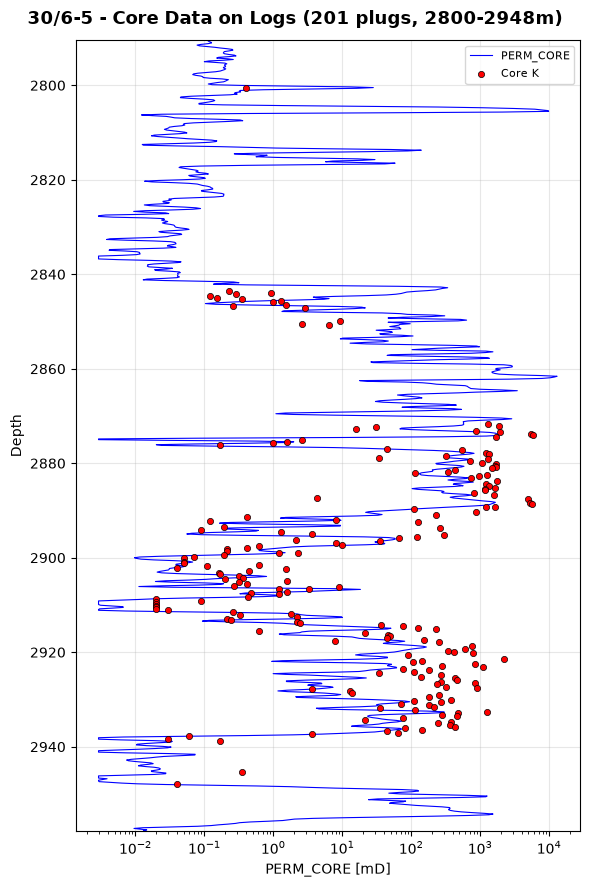

In [11]:
# Overlay: continuous predicted perm vs the discrete core plugs, over the cored
# interval. PERM_CORE is a curve name plot_core_on_logs recognises, so the core
# permeability plugs are overlaid automatically as markers on the log-scale track.
from petrophys.visualization.core import plot_core_on_logs

fig, axes = plot_core_on_logs(
    well, core,
    curves=["PERM_CORE"],
    depth_range=(core.top - 10, core.bottom + 10),
    figsize=(6, 9),
)
plt.show()

---
## Part 2 - Rock typing with the digital-core toolkit

Plug-based core analysis samples one point every ~30 cm. Modern **core scanning**
delivers *continuous* high-resolution logs: laser grain size, XRF elemental
chemistry, scratch-test strength, ultrasonic velocities, and RGB colour. The
`petrophys.interpretation.core_analysis` digital-core suite ingests these and turns them into
interpretation-ready products: `XRFData` (mineral proxies, elemental ratios),
`GrainSizeData` (Wentworth classes, sorting, Kozeny-Carman permeability), and
`CoreMechanical` (dynamic elastic moduli from Vp/Vs).

> **Data note.** 30/6-5 carries no scanner data, so those three tools are not
> demonstrated on that well. The separate Epslog collection for 15/12-20 S
> now supplies scanner inputs (see sections 2.2-2.4). Here `DigitalCoreFacies`
> is applied to real wireline logs over the cored interval of 30/6-5 - a
> standard electrofacies workflow.

### 2.1 Facies classification with weighted K-means

`DigitalCoreFacies` standardises each input feature, applies an optional
`sqrt(weight)` emphasis, and runs K-means. The result is a `FaciesResult`
carrying the per-sample labels, cluster centroids (back in original units), and
convenience methods `proportions()` and `statistics()`.

Here we use **real 30/6-5 wireline logs** (GR, RHOB, NPHI, PEF) over the cored
interval as the multi-parameter feature set - a legitimate electrofacies
exercise - to keep the demonstration grounded in real data.

In [12]:
from petrophys.interpretation.core_analysis import DigitalCoreFacies

# Real logs over the cored interval as clustering features.
top, bottom = core.top, core.bottom
dep = np.asarray(well.depth, dtype=float)
m = (dep >= top) & (dep <= bottom)

features = {
    'GR':   np.asarray(well.get('GR').data,   dtype=float)[m],
    'RHOB': np.asarray(well.get('RHOB').data, dtype=float)[m],
    'NPHI': np.asarray(well.get('NPHI').data, dtype=float)[m],
    'PEF':  np.asarray(well.get('PEF').data,  dtype=float)[m],
}
depth_m = dep[m]
print('Samples in interval:', depth_m.size)
print('Finite per feature :', {k: int(np.isfinite(v).sum()) for k, v in features.items()})

Samples in interval: 968
Finite per feature : {'GR': 968, 'RHOB': 968, 'NPHI': 968, 'PEF': 968}


In [13]:
clf = DigitalCoreFacies(n_facies=4, n_init=10, random_state=42)
result = clf.fit(depth_m, features, weights={'GR': 2.0})   # emphasise GR (shaliness)

print('Facies model fitted.')
print('  n_facies :', result.n_facies)
print('  inertia  : %.1f' % result.inertia)
print('  labels   :', np.unique(result.facies[result.facies > 0]))
print()
print('Facies proportions:')
for fc, frac in result.proportions().items():
    print('  facies %d : %5.1f %%' % (fc, 100 * frac))

Facies model fitted.
  n_facies : 4
  inertia  : 1264.9
  labels   : [1 2 3 4]

Facies proportions:
  facies 1 :  38.1 %
  facies 2 :  48.0 %
  facies 3 :   4.5 %
  facies 4 :   9.3 %


#### Per-facies statistics table

`statistics()` returns the P13 / P50 / P87 of every feature within each facies -
the fingerprint that lets you *name* the clusters (clean sand, shale,
calcite-cemented streak, etc.).

In [14]:
stats = result.statistics(features)
# Show the median (P50) of each feature per facies for a compact fingerprint.
p50_cols = [c for c in stats.columns if c.endswith("_P50")]
summary = stats[["count", "proportion_pct"] + p50_cols].round(2)
summary.columns = ["count", "prop_%"] + [c.replace("_P50", "_median") for c in p50_cols]

# Cluster numbers are arbitrary labels: identify clusters by their fingerprint.
print("Cleanest facies (lowest median GR)  :", summary["GR_median"].idxmin())
print("Shaliest facies (highest median GR) :", summary["GR_median"].idxmax())
summary

Cleanest facies (lowest median GR)  : 2
Shaliest facies (highest median GR) : 1


,count,prop_%,GR_median,RHOB_median,NPHI_median,PEF_median
facies,,,,,,
1,369,38.12,97.31,2.57,0.29,3.92
2,465,48.04,39.09,2.34,0.21,4.36
3,44,4.55,88.81,2.24,0.41,9.62
4,90,9.30,94.91,2.32,0.37,5.43


#### Facies on a cross-plot

A density-neutron cross-plot coloured by facies shows how the clusters
separate in petrophysical space. One display detail matters: **a facies label
is a category, not a number**. A continuous colorbar is the wrong tool - it
invents in-between colours and ticks (facies 2.5 does not exist) and leaves
the reader guessing which colour maps to which cluster. So we scatter each
facies as its own series with a discrete colour, and put the cluster
fingerprint (sample count and median GR) straight into the legend.

Read it against the statistics table above. K-means cluster numbers are
arbitrary (they can change with the library version or random seed), so name
each cluster by its fingerprint:

- The **lowest-GR facies** sits at low NPHI and low RHOB: the clean, porous
  reservoir sand.
- A **high-GR facies at higher RHOB** is shale. The neutron reads high because
  clay-bound hydrogen counts as apparent porosity.
- Smaller high-GR clusters pushed to **very high NPHI and low RHOB**, or with an
  unusually high PEF, are shale streaks with anomalous log response - bad hole
  or heavy minerals rather than a clean mineralogy signal. Clusters inherit
  whatever artefacts the input logs carry.

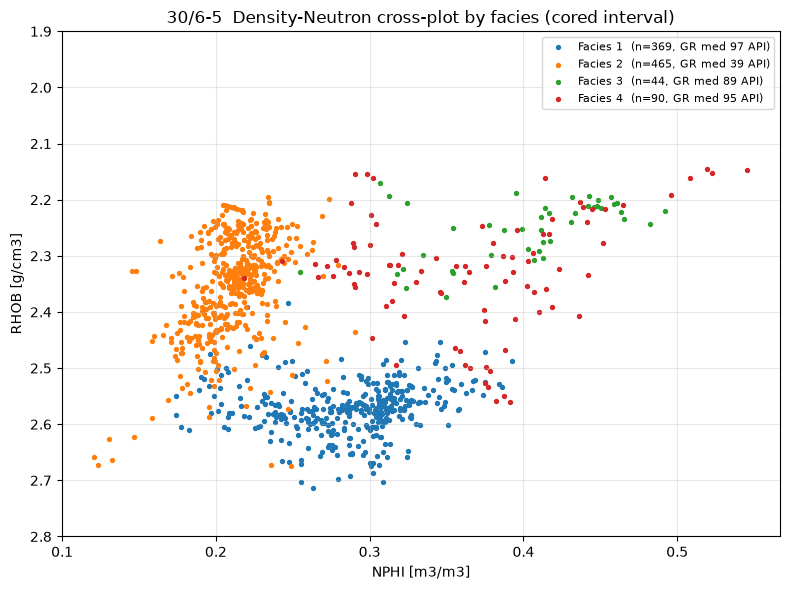

In [15]:
# FACIES is a category, so no colorbar: one scatter series per facies with a
# discrete colour, and the fingerprint (n, median GR) carried in the legend.
nphi_s, rhob_s, gr_s = features['NPHI'], features['RHOB'], features['GR']

fig, ax = plt.subplots(figsize=(8, 6))
palette = plt.get_cmap('tab10').colors
for k, fc in enumerate(np.unique(result.facies[result.facies > 0])):
    sel = result.facies == fc
    ax.scatter(nphi_s[sel], rhob_s[sel], s=8, color=palette[k],
               label='Facies %d  (n=%d, GR med %.0f API)'
                     % (fc, sel.sum(), np.nanmedian(gr_s[sel])))
ax.set_xlabel('NPHI [m3/m3]')
ax.set_ylabel('RHOB [g/cm3]')
ax.set_ylim(2.8, 1.9)   # density increases downward
ax.grid(alpha=0.3)
ax.legend(loc='upper right', fontsize=8)
ax.set_title('30/6-5  Density-Neutron cross-plot by facies (cored interval)')
plt.tight_layout()
plt.show()

### 2.2 XRF geochemistry and mineral proxies

> **Inputs bundled; exercise pending.** `pp.sample("epslog_15_12_20_s_c01_xrf")`
> and the corresponding `c02` sample supply 1,699 XRF depth samples from
> 15/12-20 S. Load with `XRFData.from_las(path, error_suffix="_ER")`, then
> use `elemental_ratios`, `mineral_proxies` and `create_xrf_panel`.
> These are elemental measurements and proxy indices, not XRD mineral fractions.
> A comparison with conventional wireline logs still needs logs from this same
> well and a verified depth tie. See [Epslog dataset notes](https://github.com/sambalshikhar/petrophys/blob/main/src/petrophys/datasets/epslog/README.md).


### 2.3 Grain size and Kozeny-Carman permeability

> **Inputs bundled; calibration checks pending.** The Epslog `c01`/`c02`
> `grain_segmentation` samples provide P20/P50/P80 image-derived sizes; load
> `P50GSDDML` as d50 and leave d13/d87 unset. The `grain_laser` samples retain
> a separate laser-derived proxy. `pp.sample("epslog_15_12_20_s_core")` provides
> 356 same-well routine-core records. There are 214 complete P50/porosity/Kh
> matches within 0.05 m on nominal core depth. Confirm depth alignment and
> original permeability units before quantitative calibration; P20/P80 cannot
> substitute for P13/P87. See [Epslog dataset notes](https://github.com/sambalshikhar/petrophys/blob/main/src/petrophys/datasets/epslog/README.md) for mappings and verification.


### 2.4 Core mechanical properties

> **Scanner inputs bundled; static comparison incomplete.** The Epslog
> `c01`/`c02` `strength_sonic` samples load through `CoreMechanical` with
> `E_STR001`, `E_UVELP005`, `E_UVELS005` and `E_PR005`. These supply scanner
> strength, core ultrasonic velocities and dynamic Poisson ratio.
> Static Young's modulus, static Poisson ratio, independent plug UCS tests
> and matching DTC/DTS wireline logs are still needed for the proposed
> static-versus-dynamic comparison. Dynamic elastic moduli also require bulk
> density; grain density is not a substitute. See [Epslog dataset notes](https://github.com/sambalshikhar/petrophys/blob/main/src/petrophys/datasets/epslog/README.md).


---
## Part 3 - Geochemistry from spectral gamma (25/5-1)

A total gamma-ray (GR) log counts every gamma ray the formation emits. Nearly
all of them come from three natural sources: potassium-40 and the thorium and
uranium decay series. A **spectral gamma-ray** tool splits the energy spectrum
into those three elements and reports them as concentrations: potassium in %,
thorium and uranium in ppm.

The elements behave differently in sediments, which is what makes the split
useful:

- **Thorium** is insoluble. It travels with detrital clay and heavy minerals,
  so it is the most dependable radioactive clay indicator.
- **Uranium** dissolves in oxidising water and precipitates where conditions
  turn reducing, typically with organic matter. It follows redox conditions and
  organic content, not clay.
- **Potassium** sits in illite, micas and K-feldspar.

A GR-based clay volume assumes that all radioactivity comes from clay. Spectral
gamma lets you test that assumption. None of the bundled wells has core-scanner
geochemistry (XRF), so this part uses the downhole geochemistry that *was*
measured: the GeoLink well **25/5-1** (Frøy field, Norwegian North Sea)
carries processed thorium (`THOR`) and uranium (`URAN`) curves.

### 3.1 Inspect the spectral curves: units, coverage, plausibility

Before interpreting anything, check what the file holds: the units, the depth
interval each curve covers, and whether the values are physically plausible.

In [16]:
well25 = pp.read(pp.sample("25_5-1"))
depth25 = np.asarray(well25.depth, dtype=float)

print("Well :", well25.name)
print("Depth: %.1f - %.1f %s" % (well25.start_depth, well25.stop_depth, well25.depth_unit))
for name in ("GR", "THOR", "URAN"):
    curve = well25.get(name)
    values = np.asarray(curve.data, dtype=float)
    has_value = np.isfinite(values)
    print("  %-4s [%-4s] logged %.1f - %.1f m (%d samples)  description: %s"
          % (name, curve.unit, depth25[has_value].min(), depth25[has_value].max(),
             has_value.sum(), curve.metadata.description))

Well : 25/5-1 Froey
Depth: 590.2 - 3432.1 m
  GR   [gAPI] logged 590.2 - 3432.1 m (18649 samples)  description: GR
  THOR [ppm ] logged 2905.7 - 3432.1 m (3455 samples)  description: THOR
  URAN [ppm ] logged 2905.7 - 3432.1 m (3455 samples)  description: URAN


The spectral curves cover only the deepest part of the well, while GR runs
almost its whole length. The units are the standard ones (ppm for Th and U,
API for GR).

Now look at the bottom of the spectral run. A real reading never repeats
exactly, to every stored decimal, for many samples in a row.
`find_held_readings` (in `petrophys.preprocessing.quality`) counts, for each
curve, the samples identical to the sample above inside a run of at least
`min_run` equal samples (10 by default, so the short repeats of quantized
curves such as a caliper in gauge hole are not flagged).

In [17]:
from petrophys.preprocessing.quality import find_held_readings

gr25 = np.asarray(well25.get("GR").data, dtype=float)
th_raw = np.asarray(well25.get("THOR").data, dtype=float)
u_raw = np.asarray(well25.get("URAN").data, dtype=float)

held = find_held_readings(well25, ["GR", "THOR", "URAN"])
for name, row in held.summary().iterrows():
    print("%-4s: %d samples repeat the one above; all lie between %.1f and %.1f m"
          % (name, row["held_samples"], row["top"], row["bottom"]))
held_from = held.shallowest_depth
print()

# Every 5th sample from just above the first repeat down to the end of the file.
logged = np.isfinite(gr25) & np.isfinite(th_raw) & np.isfinite(u_raw)
near_td = logged & (depth25 >= held_from - 0.5)
print(pd.DataFrame({"Depth (m)": depth25[near_td], "GR (API)": gr25[near_td],
                    "THOR (ppm)": th_raw[near_td], "URAN (ppm)": u_raw[near_td]})
      .iloc[::5].round(2).to_string(index=False))

# Keep only the part of the run above the held readings.
sg_ok = logged & (depth25 < held_from)
print()
print("Usable spectral window: %.1f - %.1f m (%d samples)"
      % (depth25[sg_ok].min(), depth25[sg_ok].max(), sg_ok.sum()))

GR  : 57 samples repeat the one above; all lie between 3423.4 and 3432.0 m
THOR: 45 samples repeat the one above; all lie between 3425.0 and 3432.1 m
URAN: 45 samples repeat the one above; all lie between 3425.0 and 3432.1 m

 Depth (m)  GR (API)  THOR (ppm)  URAN (ppm)
   3422.97     79.19       10.39        5.87
   3423.73     80.19       10.07        6.33
   3424.49     80.19        9.67        6.72
   3425.26     80.19        9.60        6.79
   3426.02     80.19        9.60        6.79
   3426.78     80.19        9.60        6.79
   3427.54     80.19        9.60        6.79
   3428.30     80.19        9.60        6.79
   3429.07     80.19        9.60        6.79
   3429.83     80.19        0.00        0.00
   3430.59     80.19        0.00        0.00
   3431.35     80.19        0.00        0.00
   3432.11      0.13        0.00        0.00

Usable spectral window: 2905.7 - 3423.3 m (3397 samples)


Every repeat sits in the last few metres of the file. There, GR, Th and U
freeze at one value each, and then Th and U drop to exact zeros. This pattern is
typical of the bottom of a logging run: each sensor sits some distance above the
bottom of the tool string, so it never reaches the last metres of hole, and the
gap is filled with a held value or zeros. GR freezes a little higher than Th and
U, so it was probably recorded by a separate sensor. These are not
measurements, so the analysis window `sg_ok` stops above the first repeat in
any of the three curves. Check the bottom of every run before using a curve.

Next, plausibility. Average crustal abundances (Turekian and Wedepohl, 1961)
give a scale: an average sandstone holds about 1.7 ppm Th and 0.45 ppm U, an
average shale about 12 ppm Th and 3.7 ppm U.

In [18]:
# Average abundances (ppm) from Turekian & Wedepohl (1961), for scale only.
reference = pd.DataFrame({"THOR": [1.7, 12.0], "URAN": [0.45, 3.7]},
                         index=["average sandstone", "average shale"])
observed = pd.DataFrame(
    {"THOR": np.percentile(th_raw[sg_ok], [5, 50, 95]),
     "URAN": np.percentile(u_raw[sg_ok], [5, 50, 95])},
    index=["25/5-1 P5", "25/5-1 P50", "25/5-1 P95"],
)
print(pd.concat([observed, reference]).round(2).to_string())

negative_u = u_raw[sg_ok & (u_raw < 0)]
print()
print("Negative uranium readings: %d samples, minimum %.2f ppm; %d of them lie within 0.5 ppm of zero"
      % (negative_u.size, negative_u.min(), np.sum(negative_u > -0.5)))

                    THOR   URAN
25/5-1 P5           2.23   0.14
25/5-1 P50         11.01   1.48
25/5-1 P95         15.53  13.21
average sandstone   1.70   0.45
average shale      12.00   3.70

Negative uranium readings: 96 samples, minimum -0.98 ppm; 84 of them lie within 0.5 ppm of zero


Thorium spans the range from an average sandstone to an average shale, as
expected in a sand-shale sequence. Median uranium is ordinary, but the P95 is
several times the average-shale value: somewhere in the window there is a
uranium-rich interval.

The negative uranium readings are physically impossible. They are counting
noise: the tool derives U by stripping the other elements' contributions out of
a spectrum, and at low concentrations that difference can dip below zero. Keep
them (clipping them to zero would bias averages upward), but do not trust
single-sample ratios where uranium is this small.

One more check: is GR consistent with the spectral curves? Uranium and thorium
contribute to GR with known sensitivities, stored in the library as
`DEFAULT_API_COEFFICIENTS`. A least-squares fit of GR on Th and U should roughly
recover them. The constant term stands in for the unmeasured potassium.

In [19]:
from petrophys.interpretation.geochemistry import DEFAULT_API_COEFFICIENTS

X = np.column_stack([th_raw[sg_ok], u_raw[sg_ok], np.ones(sg_ok.sum())])
coef, *_ = np.linalg.lstsq(X, gr25[sg_ok], rcond=None)
gr_model = X @ coef
r2_gr = 1 - np.sum((gr25[sg_ok] - gr_model) ** 2) / np.sum((gr25[sg_ok] - gr25[sg_ok].mean()) ** 2)

print("Fitted : GR = %.2f*Th + %.2f*U + %.1f   (R^2 = %.3f)" % (coef[0], coef[1], coef[2], r2_gr))
print("Nominal: %.2f API/ppm Th, %.2f API/ppm U"
      % (DEFAULT_API_COEFFICIENTS["THORIUM"], DEFAULT_API_COEFFICIENTS["URANIUM"]))
print("Fitted / nominal: Th %.2f, U %.2f"
      % (coef[0] / DEFAULT_API_COEFFICIENTS["THORIUM"], coef[1] / DEFAULT_API_COEFFICIENTS["URANIUM"]))

Fitted : GR = 4.66*Th + 6.90*U + 14.1   (R^2 = 0.952)
Nominal: 3.93 API/ppm Th, 8.09 API/ppm U
Fitted / nominal: Th 1.19, U 0.85


Thorium and uranium alone explain almost all of the GR variance ($R^2$ above),
and the fitted sensitivities are of the same size as the nominal ones (ratios
printed). So GR and the spectral curves agree, and GR can serve as the total
gamma ray for the spectral interpretation. The thorium coefficient comes out a
little high partly because potassium, which the fit cannot see, rises and falls
with thorium in clays.

### 3.2 Run the spectral-gamma interpretation

`interpret_spectral_gamma` (in `petrophys.interpretation.geochemistry`) finds
processed potassium, thorium, uranium, total spectral gamma (SGR) and
uranium-free gamma (CGR) curves by mnemonic, unit and description. It converts
them to standard units (K in %, Th and U in ppm, gamma rays in API) and derives
every ratio and reconstruction its inputs allow. `pp.interpret` does not run it
(the step is listed in `result.specific_steps_skipped`), so call it directly.

A first call with `add_curves=False` changes nothing and reports what the
function finds by itself.

In [20]:
from petrophys.interpretation.geochemistry import interpret_spectral_gamma

probe = interpret_spectral_gamma(well25, add_curves=False)
print("Found by itself:", probe.sources)
print("Derived        :", sorted(probe.derived))

Found by itself: {'THORIUM': 'THOR', 'URANIUM': 'URAN'}
Derived        : ['SGR_URANIUM_API', 'U_TH_RATIO']


It resolved `THOR` and `URAN`, but not a total spectral gamma ray. The mnemonic
`GR` does not say the curve came from the spectral tool, and the held readings
in 3.1 suggest a separate sensor, so the function is right not to assume it.
What the uranium share needs, though, is a total gamma ray consistent with the
Th and U curves, and the fit in 3.1 showed that GR is. So we tell the function
to use GR as SGR with `alias_overrides`.

That adds the uranium share of the total gamma ray, `SGR_URANIUM_FRACTION`, and
a screening flag, `SGR_URANIUM_EXCESS_FLAG`, set where uranium supplies at
least `uranium_fraction_threshold` of it (we pass the default, 0.5,
explicitly). With `add_curves=True` (the default) the standardised and derived
curves are written onto `well25`.

In [21]:
U_SHARE = 0.5   # flag samples where uranium supplies at least half of the gamma ray (library default)
sg = interpret_spectral_gamma(well25, alias_overrides={"SGR": ["GR"]},
                              uranium_fraction_threshold=U_SHARE)

print("Inputs used     :", sg.sources)
print("Unit conversions:", sg.conversions)
print("Derived         :", sorted(sg.derived))
print("Curves added    :", sg.output_curves)
print("Warnings        :", sg.warnings or "none")
print("Not in this well:", [name for name in ("POTASSIUM", "CGR") if name not in sg.sources])

Inputs used     : {'THORIUM': 'THOR', 'URANIUM': 'URAN', 'SGR': 'GR'}
Unit conversions: {'THORIUM': 'identity_ppm', 'URANIUM': 'identity_ppm', 'SGR': 'identity_api'}
Derived         : ['SGR_URANIUM_API', 'SGR_URANIUM_EXCESS_FLAG', 'SGR_URANIUM_FRACTION', 'U_TH_RATIO']
Curves added    : ['THORIUM', 'URANIUM', 'SGR', 'U_TH_RATIO', 'SGR_URANIUM_API', 'SGR_URANIUM_FRACTION', 'SGR_URANIUM_EXCESS_FLAG']
Warnings        : none
Not in this well: ['POTASSIUM', 'CGR']


- `THORIUM` and `URANIUM` are standardised copies of the inputs (the units were
  already ppm, hence `identity_ppm`).
- `U_TH_RATIO` is uranium over thorium.
- `SGR_URANIUM_API` is uranium's contribution to the gamma ray,
  8.09 API per ppm U. `SGR_URANIUM_FRACTION` divides it by the total, and
  `SGR_URANIUM_EXCESS_FLAG` marks samples where the fraction reaches the
  threshold.
- There is **no potassium**, so everything that needs it is absent:
  `TH_K_RATIO`, `U_K_RATIO`, and the reconstructed gamma rays `CGR_CALC` and
  `SGR_CALC`. Section 3.6 explains what they would have added.

The function processes every sample it is given, including the held readings
at the bottom of the run. Masking them with `sg_ok` is our job.

### 3.3 Th/U ratio and depositional environment

Thorium stays with detrital minerals while uranium moves with redox conditions,
so their ratio records the chemistry of the depositional environment. The
standard thresholds come from Adams and Weaver (1958) and were popularised for
well logs by Fertl (1979):

| Th/U | Library class | Typical setting |
|---|---|---|
| > 7 | `continental oxidising` | uranium leached out (weathered, terrestrial sediments) |
| 2 - 7 | `marine` | grey and green shales, greywackes |
| < 2 | `marine reducing` | black, organic-rich shales that fix uranium |

`classify_th_u_environment` (in `petrophys.interpretation.geochemistry`)
applies these thresholds (`TH_U_ENVIRONMENT_THRESHOLDS`). It computes Th/U
only where uranium is at least `uranium_floor_ppm`, 0.5 ppm here. Most of the
negative readings above lie within 0.5 ppm of zero, so below that level a
single uranium sample is mostly noise and its ratio means nothing. (The
spectral-gamma result reports the reciprocal, `U_TH_RATIO`, which stays finite
as uranium approaches zero.)

The window is split with the library's uranium flag. The GeoLink lithology labels
in the file (`LITHOLOGY_GEOLINK`) give an independent description of the rock
in each part.

In [22]:
from petrophys.interpretation.geochemistry import classify_th_u_environment
from petrophys.visualization.log_viewer import GEOLINK_LITHOLOGY_CODE_LABELS

U_FLOOR_PPM = 0.5
th25 = sg.measurements["THORIUM"]
u25 = sg.measurements["URANIUM"]

env = classify_th_u_environment(th25, u25, uranium_floor_ppm=U_FLOOR_PPM)
rated = sg_ok & env.rated
th_u = np.where(sg_ok, env.th_u_ratio, np.nan)

u_flag = sg_ok & (sg.derived["SGR_URANIUM_EXCESS_FLAG"] == 1)
env_table = env.summary({"whole window": sg_ok,
                         "uranium-dominated": u_flag,
                         "rest of window": sg_ok & ~u_flag}).round(1)

print("Th/U rated on %d of %d samples (uranium >= %.1f ppm)" % (rated.sum(), sg_ok.sum(), U_FLOOR_PPM))
print()
print(env_table.to_string())

# Independent description: GeoLink lithology labels in each part of the window.
lith_code = np.asarray(well25.get("LITHOLOGY_GEOLINK").data, dtype=float)
lith_counts = {}
for label, sel in (("uranium-dominated", u_flag), ("rest of window", sg_ok & ~u_flag)):
    codes = lith_code[sel & np.isfinite(lith_code)].astype(int)
    lith_counts[label] = pd.Series(codes).map(GEOLINK_LITHOLOGY_CODE_LABELS).value_counts()
print()
print("GeoLink lithology labels (samples):")
print(pd.DataFrame(lith_counts).fillna(0).astype(int).to_string())

Th/U rated on 2944 of 3397 samples (uranium >= 0.5 ppm)

                   samples  median Th/U  marine reducing (%)  marine (%)  continental oxidising (%)
whole window          2944          5.8                 16.0        45.2                       38.8
uranium-dominated      373          0.8                 95.4         4.3                        0.3
rest of window        2571          6.5                  4.4        51.1                       44.4

GeoLink lithology labels (samples):
                   uranium-dominated  rest of window
Calcareous Cement                  3              24
Coal                               4              17
Cross Bedded Sst                   5             774
Shaly Silt                        99            1208
Silt                              71             927
Silty Sand                         0              44
Silty Shale                      178               3


The depth plot shows where the flag falls. Each shaded band is a contiguous
run of uranium-dominated samples: `flag_intervals` (in
`petrophys.evaluation.intervals`) turns the per-sample flag into a table of
depth intervals, here joining flagged samples less than 1 m apart. Each
interval spans the full sample cells, so a thickness includes half a sample
step at each end. The right track shows Th/U on a log scale with
the three environment classes as background bands; the dark line is a running
median over 11 samples (about 1.7 m), because a single sample is noisy.

Uranium-dominated runs: 10. The thickest spans 2908.2 - 2960.2 m;
the other 9 are each at most 2.0 m thick (5.6 m in total)


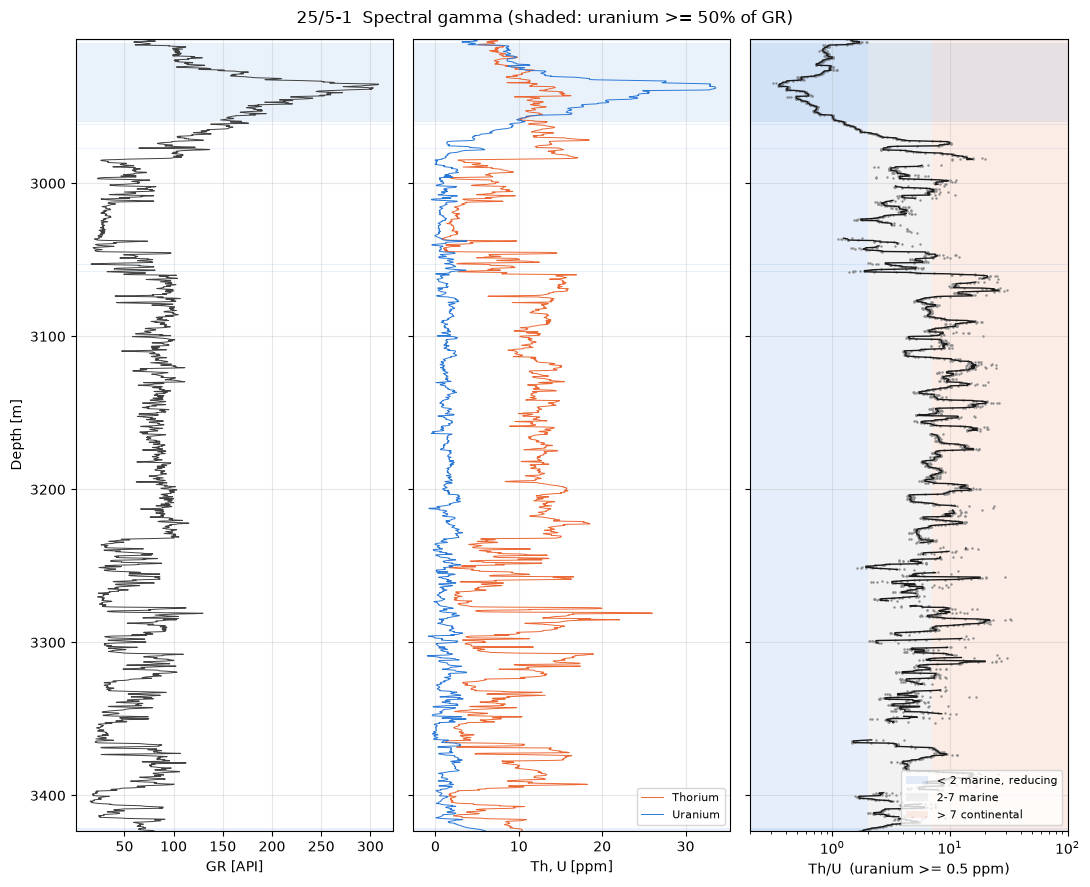

In [23]:
from petrophys.evaluation.intervals import flag_intervals

u_runs = flag_intervals(u_flag, depth25, max_gap=1.0)
longest = u_runs.loc[u_runs["thickness"].idxmax()]
others = u_runs.drop(index=longest.name)
print("Uranium-dominated runs: %d. The thickest spans %.1f - %.1f m;"
      % (len(u_runs), longest["top"], longest["bottom"]))
print("the other %d are each at most %.1f m thick (%.1f m in total)"
      % (len(others), others["thickness"].max(), others["thickness"].sum()))

COLOR_TH, COLOR_U, COLOR_GR = "#eb6834", "#2a78d6", "0.25"
top25, base25 = depth25[sg_ok].min(), depth25[sg_ok].max()
th_u_smooth = pd.Series(th_u).rolling(11, center=True, min_periods=6).median()

fig, axes = plt.subplots(1, 3, figsize=(11, 9), sharey=True)
axes[0].plot(np.where(sg_ok, gr25, np.nan), depth25, color=COLOR_GR, lw=0.7)
axes[0].set_xlabel("GR [API]")
axes[1].plot(np.where(sg_ok, th25, np.nan), depth25, color=COLOR_TH, lw=0.7, label="Thorium")
axes[1].plot(np.where(sg_ok, u25, np.nan), depth25, color=COLOR_U, lw=0.7, label="Uranium")
axes[1].set_xlabel("Th, U [ppm]")
axes[1].legend(loc="lower right", fontsize=8)

ax = axes[2]
for lo, hi, colour, name in ((0.1, 2, COLOR_U, "< 2 marine, reducing"),
                             (2, 7, "0.6", "2-7 marine"),
                             (7, 1000, COLOR_TH, "> 7 continental")):
    ax.axvspan(lo, hi, color=colour, alpha=0.12, lw=0, label=name)
ax.scatter(th_u, depth25, s=3, color="0.55", lw=0)
ax.plot(th_u_smooth, depth25, color="0.1", lw=1.0)
ax.set_xscale("log")
ax.set_xlim(0.2, 100)
ax.set_xlabel("Th/U  (uranium >= %.1f ppm)" % U_FLOOR_PPM)
ax.legend(loc="lower right", fontsize=8)

for a in axes:
    for run in u_runs.itertuples():
        a.axhspan(run.top, run.bottom, color=COLOR_U, alpha=0.10, lw=0)
    a.grid(alpha=0.3)
axes[0].set_ylim(base25, top25)
axes[0].set_ylabel("Depth [m]")
fig.suptitle("25/5-1  Spectral gamma (shaded: uranium >= %.0f%% of GR)" % (100 * U_SHARE))
plt.tight_layout()
plt.show()

Reading the table and the plot together:

- **The uranium-dominated interval** is concentrated in the thickest run near
  the top of the window, where GR reaches its highest values. There, almost
  every sample has Th/U below 2, the signature of a **marine, reducing,
  organic-rich shale**. The GeoLink labels agree: this part is mostly silty shale and
  shaly silt, and it holds nearly all of the window's silty-shale samples. In
  the northern North Sea, the Upper Jurassic Draupne and Heather formations,
  which cap the Middle Jurassic reservoirs, are the classic uranium-rich "hot
  shales". The file carries no formation tops, though, so treat that name as a
  hypothesis to check against a tops list.
- **The rest of the window** straddles the marine/continental boundary: its
  median Th/U sits just below 7, with large shares on both sides. That fits a
  mixed shallow-marine to continental setting such as a delta. The coal among the
  lithology labels, which forms on land, supports it.
- **The other flagged runs** are thin (their thicknesses are printed above).
  Uranium also concentrates in fractures, phosphatic beds and at
  unconformities, so read thin spikes individually rather than as an
  environment.

Th/U is a screening indicator. Read it over intervals rather than sample by
sample, and confirm it with other evidence (tops, lithology, cuttings, core).

### 3.4 A thorium clay indicator versus the GR clay volume

The simplest clay indicator from any radioactive curve is the linear index

$$I_x = \frac{x - x_{clean}}{x_{shale} - x_{clean}}, \quad \text{clipped to } 0-1.$$

For GR it is the familiar **IGR**, the linear GR clay volume (the upper bound of
the non-linear Larionov, Steiber and Clavier corrections). Applied to thorium,
it gives **ITh**, a clay indicator that uranium cannot disturb.

To compare like with like, both indices use the same baseline rule over the
same window: clean = P5 and shale = P95 of the usable spectral window.
`thorium_clay_index` (in `petrophys.interpretation.geochemistry`) picks those
baselines inside a mask and returns them with the index. For GR we call
`vcl_linear` from `petrophys.interpretation.clay_volume` with the same
percentile baselines, rather than `vcl_from_gr`, because `vcl_from_gr` widens
any baselines inside 20-100 API to 20-100 API and would override the
window-specific picks.

In [24]:
from petrophys.interpretation.clay_volume import vcl_linear
from petrophys.interpretation.geochemistry import thorium_clay_index

gr_clean, gr_shale = np.percentile(gr25[sg_ok], [5, 95])
igr = np.where(sg_ok, vcl_linear(gr25, gr_clean, gr_shale), np.nan)
th_index = thorium_clay_index(th25, percentiles=(5, 95), mask=sg_ok)
ith = np.where(sg_ok, th_index.index, np.nan)

print("GR baselines: clean %.1f API, shale %.1f API" % (gr_clean, gr_shale))
print("Th baselines: clean %.2f ppm, shale %.2f ppm" % (th_index.clean_ppm, th_index.shale_ppm))
print("Median IGR %.2f | median ITh %.2f" % (np.nanmedian(igr), np.nanmedian(ith)))

GR baselines: clean 26.2 API, shale 170.6 API
Th baselines: clean 2.23 ppm, shale 15.53 ppm
Median IGR 0.37 | median ITh 0.66


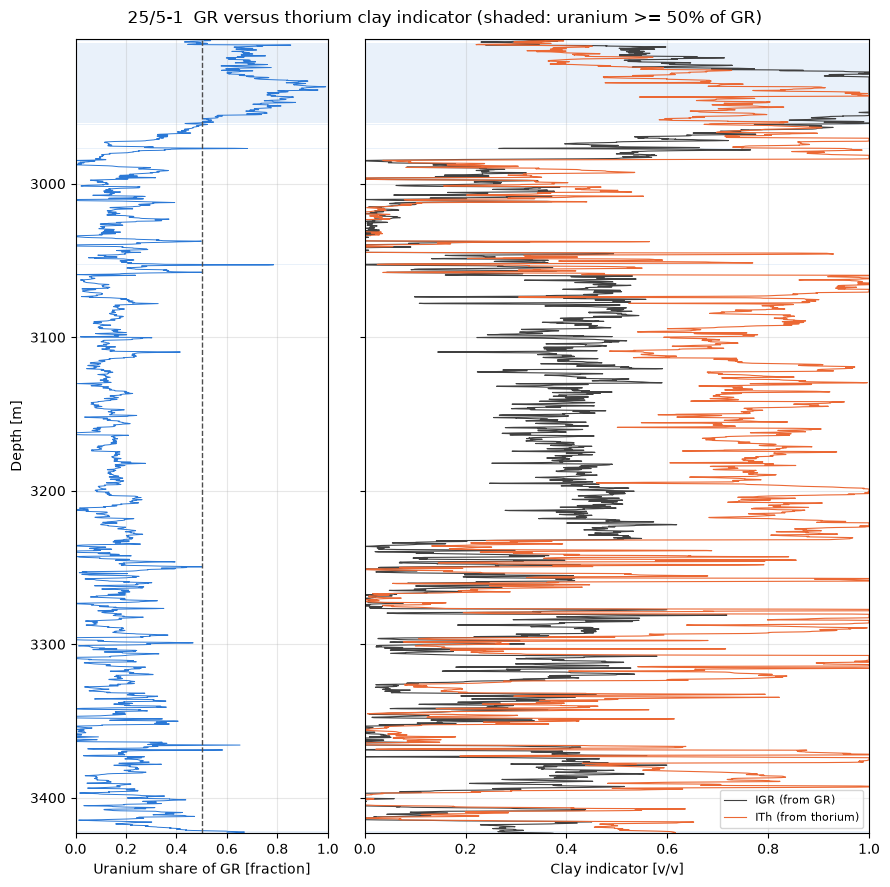

In [25]:
u_fraction = np.where(sg_ok, sg.derived["SGR_URANIUM_FRACTION"], np.nan)

fig, axes = plt.subplots(1, 2, figsize=(9, 9), sharey=True, gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]
ax.plot(u_fraction, depth25, color=COLOR_U, lw=0.7)
ax.axvline(U_SHARE, color="0.3", ls="--", lw=1)
ax.set_xlim(0, 1)
ax.set_xlabel("Uranium share of GR [fraction]")

ax = axes[1]
ax.plot(igr, depth25, color=COLOR_GR, lw=0.8, label="IGR (from GR)")
ax.plot(ith, depth25, color=COLOR_TH, lw=0.8, label="ITh (from thorium)")
ax.set_xlim(0, 1)
ax.set_xlabel("Clay indicator [v/v]")
ax.legend(loc="lower right", fontsize=8)

for a in axes:
    for run in u_runs.itertuples():
        a.axhspan(run.top, run.bottom, color=COLOR_U, alpha=0.10, lw=0)
    a.grid(alpha=0.3)
axes[0].set_ylim(base25, top25)
axes[0].set_ylabel("Depth [m]")
fig.suptitle("25/5-1  GR versus thorium clay indicator (shaded: uranium >= %.0f%% of GR)" % (100 * U_SHARE))
plt.tight_layout()
plt.show()

The crossplot separates the two populations: uranium-dominated samples
(the library flag) in blue, the rest in grey. On the dashed 1:1 line the two
indicators agree.

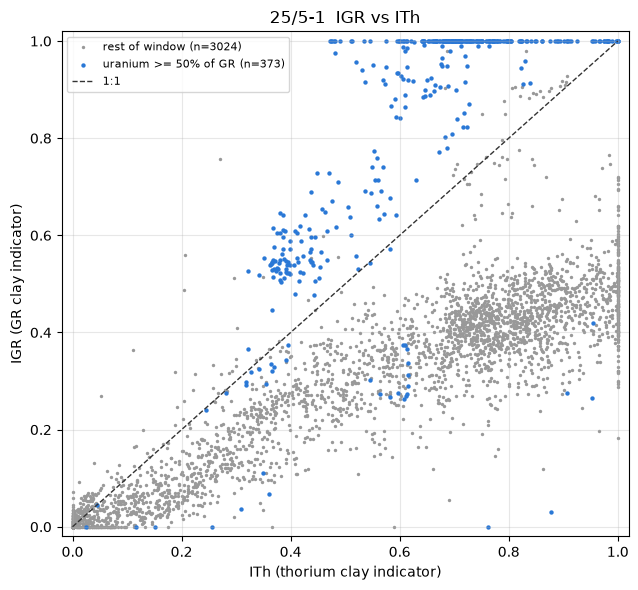

In [26]:
def clay_crossplot(index_y, ylabel, title):
    fig, ax = plt.subplots(figsize=(6.5, 6))
    rest = sg_ok & ~u_flag
    ax.scatter(ith[rest], index_y[rest], s=6, color="0.6", lw=0,
               label="rest of window (n=%d)" % rest.sum())
    ax.scatter(ith[u_flag], index_y[u_flag], s=10, color=COLOR_U, lw=0,
               label="uranium >= %.0f%% of GR (n=%d)" % (100 * U_SHARE, u_flag.sum()))
    ax.plot([0, 1], [0, 1], color="0.2", ls="--", lw=1, label="1:1")
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("ITh (thorium clay indicator)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()

clay_crossplot(igr, "IGR (GR clay indicator)", "25/5-1  IGR vs ITh")

### 3.5 Where uranium decouples GR from clay

The plots show two distinct errors. The table puts numbers on them, splitting
the window with the uranium flag.

In [27]:
def agreement(index, sel):
    diff = index[sel] - ith[sel]
    return {"samples": int(sel.sum()),
            "median uranium share of GR": np.median(u_fraction[sel]),
            "median (index - ITh)": np.median(diff),
            "mean |index - ITh|": np.mean(np.abs(diff)),
            "correlation with ITh": np.corrcoef(index[sel], ith[sel])[0, 1]}

parts = {"uranium-dominated": u_flag, "rest of window": sg_ok & ~u_flag}
igr_table = pd.DataFrame.from_dict({name: agreement(igr, sel) for name, sel in parts.items()},
                                   orient="index")
print("IGR from GR versus ITh")
print(igr_table.round(3).to_string())
print()
print("IGR saturated at 1 in %.0f%% of the uranium-dominated samples" % (100 * np.mean(igr[u_flag] >= 1.0)))

IGR from GR versus ITh
                   samples  median uranium share of GR  median (index - ITh)  mean |index - ITh|  correlation with ITh
uranium-dominated      373                       0.699                 0.202               0.221                 0.702
rest of window        3024                       0.158                -0.265               0.258                 0.885

IGR saturated at 1 in 45% of the uranium-dominated samples


Uranium corrupts the GR clay volume in two ways:

1. **Locally, it over-reads.** In the uranium-dominated beds, GR is high because
   of uranium, not clay, so IGR sits above ITh (positive median difference) and,
   in a large share of them (printed above), saturates at 1.
2. **Globally, it under-reads, through the baseline.** The shale baseline
   (P95 of GR) is set by those uranium-rich beds. Every ordinary shale then looks
   only partly shaly, and IGR sits below ITh across the rest of the window
   (negative median difference), even though the two indices correlate well there.

The fix is to take uranium out of GR before picking baselines. Without potassium
there is no tool-computed uranium-free gamma ray (CGR), but GR minus uranium's
contribution (8.09 API per ppm U) approximates it. `uranium_stripped_gamma_ray`
(in `petrophys.interpretation.geochemistry`) computes that difference; it is
the same as GR minus the spectral result's `SGR_URANIUM_API`.

GR - uranium baselines: clean 21.0 API, shale 87.3 API (GR shale baseline was 170.6)

IGR from (GR - uranium) versus ITh
                   samples  median (index - ITh)  mean |index - ITh|  correlation with ITh
uranium-dominated      373                -0.241               0.297                 0.325
rest of window        3024                 0.000               0.092                 0.920


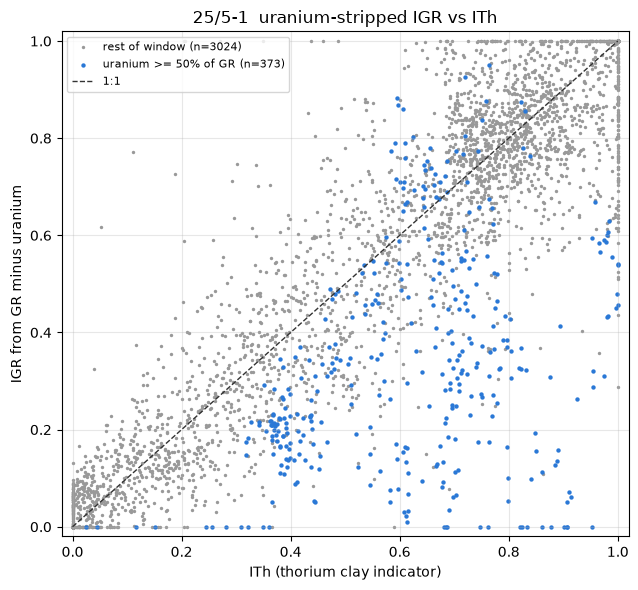

In [28]:
from petrophys.interpretation.geochemistry import uranium_stripped_gamma_ray

gr_no_u = uranium_stripped_gamma_ray(gr25, u25)          # GR - 8.09 API/ppm * U
cgr_clean, cgr_shale = np.percentile(gr_no_u[sg_ok], [5, 95])
igr_no_u = np.where(sg_ok, vcl_linear(gr_no_u, cgr_clean, cgr_shale), np.nan)
print("GR - uranium baselines: clean %.1f API, shale %.1f API (GR shale baseline was %.1f)"
      % (cgr_clean, cgr_shale, gr_shale))
print()
strip_table = pd.DataFrame.from_dict({name: agreement(igr_no_u, sel) for name, sel in parts.items()},
                                     orient="index")
print("IGR from (GR - uranium) versus ITh")
print(strip_table.drop(columns="median uranium share of GR").round(3).to_string())

clay_crossplot(igr_no_u, "IGR from GR minus uranium", "25/5-1  uranium-stripped IGR vs ITh")

With uranium removed, the shale baseline drops to a normal shale value. Outside
the uranium-dominated beds, the stripped index now lies on the 1:1 line with ITh
(median difference near zero, higher correlation). Inside them, the correction
overshoots. There, uranium supplies most of the gamma ray, so the correction is
larger than what remains, and a small error in the nominal 8.09 API/ppm
sensitivity (the fit in 3.1 found GR responds somewhat less per ppm here)
dominates the result. In uranium-rich beds, ITh is the more robust clay
indicator.

**Why this matters.** GR clay volume feeds effective porosity, shaly-sand
saturation and the net-reservoir cutoff. The local error writes off
uranium-rich rock as shale. That rock is not always a shale: uranium also
precipitates from formation water in permeable beds, so a uranium-bearing
sand can be a missed pay zone. The baseline error is less visible and hurts
more, because it biases the clay volume of every sample in the interval. When
spectral gamma is available, pick GR baselines on a uranium-free gamma ray, or
cross-check GR clay volume against thorium.

### 3.6 What potassium would have added

25/5-1 has no potassium curve (`POTASSIUM` is missing from `sg.sources`), so
the library skipped every product that needs one. With potassium the analysis
would gain:

- **A true uranium-free gamma ray.** `CGR_CALC` = 16.32·K + 3.93·Th (API), or a
  tool CGR curve. It needs neither the nominal-sensitivity stripping used above
  nor the assumption that GR and the spectral curves share a calibration.
- **The K-Th crossplot for clay typing.** Thorium plotted against potassium
  separates clay families by their Th/K ratio (`TH_K_RATIO`), following Quirein
  et al. (1982) and the service-company charts built on it. Kaolinite is
  thorium-bearing and almost potassium-free (high Th/K). Illite and micas carry
  potassium (lower Th/K). K-feldspar sits at the potassium end. Clay type
  matters downstream: it sets the cation-exchange capacity used by shaly-sand
  saturation models and the clay end-points of the density-neutron crossplot.
- **Radioactive sands.** K-feldspar and mica in an arkosic sand raise GR with
  no clay present. Only a potassium curve reveals it, and ITh cannot see it
  either.

**References for Part 3**

- Adams, J.A.S. and Weaver, C.E. (1958). Thorium-to-uranium ratios as
  indicators of sedimentary processes: example of concept of geochemical
  facies. *AAPG Bulletin* 42(2), 387-430.
- Fertl, W.H. (1979). Gamma ray spectral data assists in complex formation
  evaluation. *The Log Analyst* 20(5).
- Quirein, J.A., Gardner, J.S. and Watson, J.T. (1982). Combined natural gamma
  ray spectral / litho-density measurements applied to complex lithologies.
  SPE 11143.
- Turekian, K.K. and Wedepohl, K.H. (1961). Distribution of the elements in
  some major units of the Earth's crust. *GSA Bulletin* 72(2), 175-192.

---
## Part 4 - Calibrate against a second well's core (25/5-1)

25/5-1 also carries core plugs merged into its LAS file: `PHIC`, `KH_CORE`,
`GDEN` and `SWC`/`SOC`. Repeating the Part 1 recipe on it answers a practical
question: can a transform fitted in one well be used in another?

### 4.1 The same calibration, a second well

Same density-porosity recipe (the `RHO_MA` and `RHO_F` defined in Part 1), same
calibration call.

In [29]:
import warnings
# core_data_from_well returns core saturations as fractions. This well stores
# SWC/SOC as percent labelled 'frac', so it converts them and says so.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    core25 = core_data_from_well(well25)
for note in caught:
    print("note:", note.message)
print(core25)
print("Valid porosity / permeability plugs: %d / %d"
      % (np.isfinite(core25.porosity).sum(), np.isfinite(core25.permeability).sum()))

rhob25 = np.asarray(well25.get("RHOB").data, dtype=float)
well25.add_curve("PHID", np.clip((RHO_MA - rhob25) / (RHO_MA - RHO_F), 0.0, 0.5),
                 "v/v", "Density porosity (rho_ma=2.65)")
cal25 = calibrate_porosity(well25, core25, log_curve="PHID")

def calibration_row(c):
    return {"n": c.n_points, "R^2": c.r_squared, "bias (log-core)": c.bias, "RMSE": c.rmse}

print()
print(pd.DataFrame.from_dict({"30/6-5": calibration_row(cal), "25/5-1": calibration_row(cal25)},
                             orient="index").round(3).to_string())

note: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
note: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
CoreData(plugs=333, depth=2990.3-3286.3, props=[porosity, perm, GD, Sw])
Valid porosity / permeability plugs: 331 / 316

          n    R^2  bias (log-core)   RMSE
30/6-5  200  0.645           -0.020  0.046
25/5-1  331  0.092           -0.001  0.091


On 25/5-1 the tie between core and log porosity almost disappears. Before
blaming the rock, check the **depth tie**. Plug depths come from the driller's
pipe measurement when the core was cut, while logs are depth-measured on the
wireline cable. Offsets of a metre or more between the two are common, and each
core run can have its own. This file carries no core gamma to match against the
log GR, so we scan whole-sample shifts of the core depths with
`find_core_depth_shift` (in `petrophys.interpretation.core_analysis`). At each
shift it measures how well core porosity tracks density porosity (the Pearson
correlation), by default over +/- 30 log samples. With `run_gap` it also scans
each core run on its own, and `shift_core_depths` applies the chosen shift.

A shift picked this way is fitted to the same data it is judged on, so the
post-shift statistics are optimistic. The consistency check is the core runs:
a genuine depth error gives each run a shift of similar size.

In [30]:
from petrophys.interpretation.core_analysis import find_core_depth_shift, shift_core_depths

# Scan +/- 30 log samples; also scan each core run (runs separated by gaps
# > 1.5 m, at least 30 plugs) on its own.
scan25 = find_core_depth_shift(well25, core25, log_curve="PHID", run_gap=1.5, min_run_plugs=30)
shift25 = scan25.shift
print("Correlation core vs log porosity: %.2f at zero shift, %.2f at %+.2f m (log depth = core depth %+.2f m)"
      % (scan25.correlation_unshifted, scan25.correlation, shift25, shift25))

print()
for run in scan25.runs.itertuples():
    print("  core run %.1f - %.1f m (%d plugs): best shift %+.2f m"
          % (run.top, run.bottom, run.plugs, run.shift))

core25_tied = shift_core_depths(core25, scan25)
cal25_tied = calibrate_porosity(well25, core25_tied, log_curve="PHID")
print()
print(pd.DataFrame.from_dict({"25/5-1 as stored": calibration_row(cal25),
                              "25/5-1 depth-shifted": calibration_row(cal25_tied)},
                             orient="index").round(3).to_string())

Correlation core vs log porosity: 0.30 at zero shift, 0.66 at +2.89 m (log depth = core depth +2.89 m)

  core run 2990.3 - 3041.8 m (173 plugs): best shift +3.05 m
  core run 3235.2 - 3252.4 m (58 plugs): best shift +2.74 m
  core run 3257.3 - 3275.3 m (66 plugs): best shift +1.98 m

                        n    R^2  bias (log-core)   RMSE
25/5-1 as stored      331  0.092           -0.001  0.091
25/5-1 depth-shifted  331  0.436           -0.004  0.062


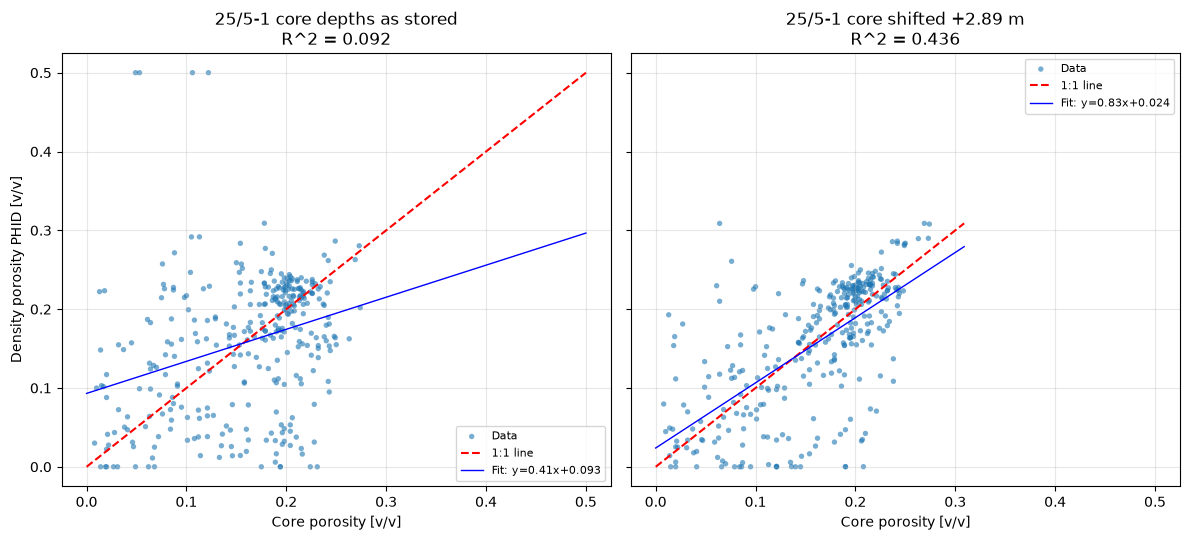

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
plot_calibration(cal25, ax=axes[0])
axes[0].set_title("25/5-1 core depths as stored\nR^2 = %.3f" % cal25.r_squared)
plot_calibration(cal25_tied, ax=axes[1])
axes[1].set_title("25/5-1 core shifted %+.2f m\nR^2 = %.3f" % (shift25, cal25_tied.r_squared))
for ax in axes:
    ax.set_xlabel("Core porosity [v/v]")
axes[0].set_ylabel("Density porosity PHID [v/v]")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

The bulk shift restores a usable tie, and the main core runs each prefer a shift
of the same sign and similar size, which points to a real depth offset rather
than a chance correlation peak. A production depth match would shift each run on
its own, ideally by matching core gamma to log GR. Here the bulk shift is enough
to compare the wells.

The **poro-perm transform** needs no depth tie at all: plug porosity and plug
permeability come from the same plug, so shifting depths cannot change it.

### 4.2 Compare the transforms

In [32]:
transform25 = fit_poro_perm_transform(core25)
corr25 = fit_porosity_correction(well25, core25_tied, log_curve="PHID")

def transform_row(t, c, core_data):
    row = {"cored interval (m)": "%.0f - %.0f" % (core_data.top, core_data.bottom),
           "A (slope)": round(t.A, 2), "B (intercept)": round(t.B, 2),
           "R^2": round(t.r_squared, 3), "plugs": t.n_points}
    for phi in (0.10, 0.20, 0.25):
        row["k at phi %.2f (mD)" % phi] = round(float(t.predict(phi)), 1)
    row["porosity correction"] = "%.3f*PHID + %.3f" % (c.A, c.B)
    return row

print(pd.DataFrame({"30/6-5": transform_row(transform, corr, core),
                    "25/5-1": transform_row(transform25, corr25, core25)}).to_string())

# Carry 30/6-5's transform to 25/5-1's plugs and score it in log10 space.
ok = np.isfinite(core25.porosity) & np.isfinite(core25.permeability) & (core25.permeability > 0)
log_k = np.log10(core25.permeability[ok])
for label, t in (("own 25/5-1 transform", transform25), ("30/6-5 transform", transform)):
    resid = log_k - np.log10(t.predict(core25.porosity[ok]))
    print("%-22s on 25/5-1 plugs: mean log10 error %+.3f (factor %.2f), RMS %.3f decades"
          % (label, resid.mean(), 10 ** resid.mean(), np.sqrt(np.mean(resid ** 2))))

                                 30/6-5              25/5-1
cored interval (m)          2800 - 2948         2990 - 3286
A (slope)                         21.72               22.28
B (intercept)                     -2.54               -2.44
R^2                               0.777               0.841
plugs                               198                 316
k at phi 0.10 (mD)                  0.4                 0.6
k at phi 0.20 (mD)                 64.2               104.1
k at phi 0.25 (mD)                782.8              1353.6
porosity correction  0.717*PHID + 0.065  0.574*PHID + 0.068
own 25/5-1 transform   on 25/5-1 plugs: mean log10 error +0.000 (factor 1.00), RMS 0.609 decades
30/6-5 transform       on 25/5-1 plugs: mean log10 error +0.189 (factor 1.54), RMS 0.639 decades


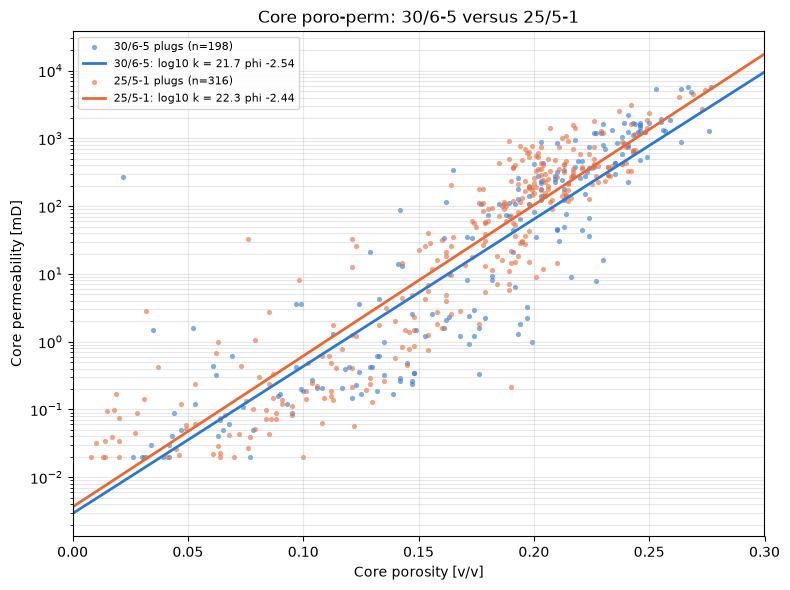

In [33]:
fig, ax = plt.subplots(figsize=(8, 6))
phi_line = np.linspace(0.0, 0.30, 100)
for name, core_data, t, colour in (("30/6-5", core, transform, "#2a78d6"),
                                   ("25/5-1", core25, transform25, "#eb6834")):
    ok = np.isfinite(core_data.porosity) & (core_data.permeability > 0)
    ax.scatter(core_data.porosity[ok], core_data.permeability[ok], s=14, color=colour,
               alpha=0.6, lw=0, label="%s plugs (n=%d)" % (name, ok.sum()))
    ax.plot(phi_line, t.predict(phi_line), color=colour, lw=2,
            label="%s: log10 k = %.1f phi %+.2f" % (name, t.A, t.B))
ax.set_yscale("log")
ax.set_xlim(0, 0.30)
ax.set_xlabel("Core porosity [v/v]")
ax.set_ylabel("Core permeability [mD]")
ax.set_title("Core poro-perm: 30/6-5 versus 25/5-1")
ax.grid(alpha=0.3, which="both")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Read the comparison in two halves.

- **The rock side (poro-perm).** Here the two transforms are close. Carried to
  25/5-1, the 30/6-5 line under-predicts by the factor printed above. That is
  small beside the scatter of the plugs around either line (the RMS error, in
  decades of permeability). This is a **finding, not a given**: you know it
  only because 25/5-1 has core of its own.
- **The log side (porosity correction).** The log-to-core porosity corrections
  have different slopes and intercepts (last table row), and on 25/5-1 no
  meaningful correction could be fitted until the depth tie was fixed.

Why transforms do not carry across wells without checking:

- **Porosity is only one control on permeability.** Grain size and sorting,
  the amount and habit of clay (pore-lining illite versus discrete kaolinite),
  and cementation all move the poro-perm line. They vary with depositional
  facies and with burial and temperature history, so they can differ between
  wells in the same field.
- **The log side belongs to one well.** A density-porosity correction absorbs
  that well's grain density, borehole conditions, mud and depth tie, none of
  which transfer.
- **Sampling differs.** Plugs are cut where the core allowed, and a transform
  is supported only over the porosity range of its own plugs (Part 1.5).
  Another well's rock may fall outside that range.

In practice, carry a transform to a new well only after testing it against that
well's core or well-test permeability. With no such data, carry the spread
between candidate transforms as uncertainty rather than a single line.

## Pitfalls and parameter choices

- **Calibrate against an *independent* log.** Comparing a curve against itself
  gives a meaningless $R^2 = 1$. We built density porosity from RHOB specifically
  so the comparison against core `PHIC` is real.
- **Depth-matching.** Core depth and log depth are rarely on the same datum.
  `calibrate_porosity` interpolates the log at the core depths *as stored*, so
  an offset silently destroys the correlation - on 25/5-1 it hid almost the
  whole tie until the core was shifted. Scan shifts (`find_core_depth_shift`)
  before trusting a poor calibration, and shift each core run on its own in
  production work.
- **Poro-perm is log-linear.** Never fit permeability in linear space; a few
  high-perm plugs will dominate the least-squares fit. `fit_poro_perm_transform`
  works in $\log_{10}$ for exactly this reason.
- **A transform is valid where the core is.** Applied outside the cored rock
  types and porosity range it extrapolates, often to the clip limits. Report
  predicted permeability for the calibrated interval, not the whole well, and
  test a transform against a new well's core before reusing it there.
- **K-means needs scaling and sensible K.** `DigitalCoreFacies` standardises
  features for you, but *you* choose `n_facies` and the weights. Too many facies
  over-fits noise; too few merges distinct rock types.
- **Check the bottom of every logging run.** Sensors above the tool bottom
  cannot reach the last metres of hole; files often fill that gap with a held
  value or zeros. Exact repeats are the tell-tale sign (`find_held_readings`).
- **Uranium is not clay.** A GR clay volume over-reads in uranium-rich beds,
  and a shale baseline picked in them makes every other shale look too clean.
  With spectral gamma, pick baselines on a uranium-free gamma ray or cross-check
  against thorium.
- **Read Th/U over intervals, with a uranium floor.** Near-zero (even negative)
  uranium readings are counting noise; a single-sample ratio built on them is
  meaningless.

## Recap

- `core_data_from_well` pulled the real core plugs of 30/6-5 into a `CoreData`.
- Density porosity calibrated against core exposes a bias and scatter that
  trace back to the assumed matrix density.
- A $\log_{10}(k)=A\phi+B$ transform propagated the core-perm plugs to a
  continuous predicted-permeability curve - trustworthy over the cored
  interval, extrapolated (and clipped) elsewhere.
- `DigitalCoreFacies` clustered real wireline logs into facies with a per-facies
  statistics fingerprint and a readable density-neutron cross-plot.
- On 25/5-1, QC removed held readings at the bottom of the spectral run, and
  `interpret_spectral_gamma` (with GR mapped to SGR) produced U/Th, the uranium
  contribution and a uranium-excess flag. There was no potassium, so no
  Th/K ratio or computed CGR.
- Th/U picked out a uranium-rich, marine reducing shale at the top of the
  spectral window above a mixed marine-continental section. A thorium clay
  indicator showed that uranium makes GR clay volume over-read in that shale
  and under-read everywhere else through the shale baseline. Stripping uranium
  from GR fixed the second error but not the first.
- 25/5-1's core needed a depth shift of a few metres before it tied to the log.
  Its poro-perm transform turned out close to 30/6-5's, a result you only know
  by checking.

## Try it yourself

> **Exercise 1.** Re-run the porosity calibration using a *neutron* porosity
> (`well.get('NPHI')`) instead of density porosity. Which log ties the core
> better, and what does the bias tell you about gas or clay effects?
>
> **Exercise 2.** Change `n_facies` in `DigitalCoreFacies` to 6 and add `PEF` to
> the weights. Does the inertia drop meaningfully, or are you just splitting
> noise? Inspect the new per-facies statistics table.
>
> **Exercise 3.** Feed the fitted `transform` a corrected porosity
> (via `corr.predict`) instead of raw `PHID`. How much does the predicted
> permeability profile shift?
>
> **Exercise 4.** Restrict the Th/U table to the depth-shifted cored interval of
> 25/5-1 (`core25_tied.top` to `core25_tied.bottom`) by passing that depth mask
> to `env.summary`. What depositional setting
> does it suggest for the cored reservoir, and does the GeoLink lithology over
> the same interval agree?
>
> **Exercise 5.** Estimate the missing potassium as
> $K \approx (GR - 3.93\,Th - 8.09\,U)/16.32$ using `DEFAULT_API_COEFFICIENTS`,
> over the usable window. Compare its sandstone and shale medians with the
> Turekian and Wedepohl averages (1.07 % and 2.66 % K). Why is this a
> consistency check and not a measurement?
>
> **Exercise 6.** Group `igr`, `igr_no_u` and `ith` by the GeoLink lithology
> label (`LITHOLOGY_GEOLINK`) and compare their medians. Which indicator ranks
> sandstone, silt, shaly silt and silty shale in the expected order, and where
> does each one fail?
>
> **Exercise 7.** Instead of one bulk shift, apply each core run's own best
> shift (`scan25.runs`) to `core25` and re-run `calibrate_porosity`.
> `shift_core_depths` accepts one shift per plug. How much of the remaining
> scatter was depth mismatch?

## What's next

Continue with **13 - ML Curve Imputation**, where pretrained models (XGBoost,
random forest and KNN) fill gaps in an existing log curve - the
machine-learning counterpart to the physics-based calibration you just did.
Lesson **18 - Multi-well / Field Study** takes the cross-well theme of Part 4
further, harmonising logs so that wells can be compared fairly.